# Augsburg, Where Water Runs
## Day 10 · Prompting only · #30DayMapChallenge 2026

Prepare OpenStreetMap layers and draw a map of the route from Hochablass to the historic centre of Augsburg, using the city's heritage documentation to select the route.

**Project by María Victoria León Parra**

Run from the `day10-prompting-only/` directory. The first run needs internet access. Later runs reuse the OpenStreetMap extract in `data/`.

In [1]:
from pathlib import Path
import json
import xml.etree.ElementTree as ET

import geopandas as gpd
import requests
from shapely.geometry import LineString, box

DATA_DIR = Path.cwd() / "data"
DATA_DIR.mkdir(exist_ok=True)
OSM_CACHE = DATA_DIR / "augsburg_osm_waterways.json"
OSM_MAP_URL = "https://api.openstreetmap.org/api/0.6/map"
# Bounds in longitude/latitude order, covering Hochablass and the old town.
BOUNDS = (10.887, 48.335, 10.945, 48.382)
WATERWAYS = {"river", "canal", "stream", "ditch", "drain"}
WGS84 = "EPSG:4326"
UTM = "EPSG:32632"

In [2]:
def download_tiles(session, bounds):
    """Split requests that exceed the OSM API's node limit."""
    response = session.get(
        OSM_MAP_URL,
        params={"bbox": ",".join(f"{value:.7f}" for value in bounds)},
        timeout=90,
    )
    if response.status_code == 400 and "too many nodes" in response.text.lower():
        west, south, east, north = bounds
        mid_lon, mid_lat = (west + east) / 2, (south + north) / 2
        for tile in (
            (west, south, mid_lon, mid_lat),
            (mid_lon, south, east, mid_lat),
            (west, mid_lat, mid_lon, north),
            (mid_lon, mid_lat, east, north),
        ):
            yield from download_tiles(session, tile)
        return
    response.raise_for_status()
    yield ET.fromstring(response.content)


def download_waterways():
    ways = {}
    with requests.Session() as session:
        session.headers["User-Agent"] = "30DayMapChallenge-2026 Day 10 Augsburg data preparation"
        for tile in download_tiles(session, BOUNDS):
            nodes = {
                node.attrib["id"]: [float(node.attrib["lon"]), float(node.attrib["lat"])]
                for node in tile.iterfind("node")
            }
            for way in tile.iterfind("way"):
                tags = {tag.attrib["k"]: tag.attrib["v"] for tag in way.iterfind("tag")}
                if tags.get("waterway") not in WATERWAYS | {"weir"}:
                    continue
                if tags.get("area") == "yes":
                    continue
                node_ids = [node.attrib["ref"] for node in way.iterfind("nd")]
                ways[way.attrib["id"]] = {
                    "osm_id": int(way.attrib["id"]),
                    "tags": tags,
                    "nodes": [int(node_id) for node_id in node_ids],
                    "coordinates": [nodes[node_id] for node_id in node_ids],
                }
    return sorted(ways.values(), key=lambda way: way["osm_id"])


if OSM_CACHE.exists():
    ways = json.loads(OSM_CACHE.read_text(encoding="utf-8"))
else:
    ways = download_waterways()
    if not ways:
        raise ValueError("OpenStreetMap returned no waterways for the study area.")
    OSM_CACHE.write_text(json.dumps(ways, ensure_ascii=False, indent=2), encoding="utf-8")

print(f"Loaded {len(ways)} OpenStreetMap ways.")

Loaded 613 OpenStreetMap ways.


In [3]:
from shapely.geometry import Point

# Match the documented route to OSM names and three unnamed connecting ways.
ROUTE_NAMES = {
    "Hauptstadtbach": "Hauptstadtbach",
    "Kaufbach": "Kaufbach",
    "Schwalllech": "Schwallech",
    "Schwallech": "Schwallech",
    "Mittlerer Lech": "Mittlerer Lech",
    "Hinterer Lech": "Hinterer Lech",
}
CONNECTORS = {
    280838555: "Hauptstadtbach",
    49262711: "Schwallech",
    49262722: "Schwallech",
}
# Two ways tagged Kaufbach continue towards Sparrenlech after the Schwallech turn.
SPARRENLECH_APPROACH = {49262706, 1068405159}
INTAKE_NODE = 256034933
CONFLUENCE_NODE = 647066183

ways_by_id = {way["osm_id"]: way for way in ways}
route = {}
for way in ways:
    osm_id = way["osm_id"]
    name = way["tags"].get("name")
    reach = CONNECTORS.get(osm_id) or ROUTE_NAMES.get(name)
    if reach and osm_id not in SPARRENLECH_APPROACH:
        route[osm_id] = reach

# Verify the route in the direction of the OSM ways, without snapping or gap filling.
route_ways = [ways_by_id[osm_id] for osm_id in route]

def reachable_nodes(start, upstream=False):
    start_index, end_index = (-1, 0) if upstream else (0, -1)
    edges = {}
    for way in route_ways:
        nodes = way["nodes"]
        edges.setdefault(nodes[start_index], []).append(nodes[end_index])

    visited = {start}
    pending = [start]
    while pending:
        for neighbor in edges.get(pending.pop(), []):
            if neighbor not in visited:
                visited.add(neighbor)
                pending.append(neighbor)
    return visited


from_intake = reachable_nodes(INTAKE_NODE)
to_confluence = reachable_nodes(CONFLUENCE_NODE, upstream=True)
if (
    set(route.values()) != set(ROUTE_NAMES.values())
    or CONFLUENCE_NODE not in from_intake
    or any(
        way["nodes"][0] not in from_intake or way["nodes"][-1] not in to_confluence
        for way in route_ways
    )
):
    raise ValueError("The selected ways do not form the documented route.")

print("Verified the OSM node chain from Hochablass to the old-town confluence.")

Verified the OSM node chain from Hochablass to the old-town confluence.


In [4]:
# Keep route, river and context separate so they can be styled independently.
records = []
for way in ways:
    tags = way["tags"]
    if tags["waterway"] not in WATERWAYS:
        continue
    osm_id = way["osm_id"]
    records.append({
        "osm_id": osm_id,
        "osm_name": tags.get("name"),
        "waterway": tags["waterway"],
        "tunnel": tags.get("tunnel"),
        "covered": tags.get("covered"),
        "route_reach": route.get(osm_id),
        "geometry": LineString(way["coordinates"]),
    })

waterways = gpd.GeoDataFrame(records, crs=WGS84)
on_route = waterways["route_reach"].notna()
# The outlet from the Eiskanal is tagged Lech in OSM but is off the river's main stem.
on_lech = (
    waterways["osm_name"].eq("Lech")
    & waterways["waterway"].eq("river")
    & waterways["osm_id"].ne(85547077)
)

intake_coordinate = next(
    coordinate
    for way in route_ways
    for node, coordinate in zip(way["nodes"], way["coordinates"])
    if node == INTAKE_NODE
)
intake = gpd.GeoDataFrame(
    [{"osm_id": INTAKE_NODE, "name": "Hochablass intake",
      "geometry": Point(intake_coordinate)}],
    crs=WGS84,
)
extent = box(*BOUNDS)
layers = {
    "hochablass_intake": intake.to_crs(UTM),
    "lech_river": waterways.loc[on_lech].clip(extent, keep_geom_type=True).to_crs(UTM),
    "documented_route": waterways.loc[on_route].to_crs(UTM),
    "context_waterways": (
        waterways.loc[~(on_route | on_lech)].clip(extent, keep_geom_type=True).to_crs(UTM)
    ),
}
if not layers["context_waterways"]["osm_name"].eq("Vorderer Lech").any():
    raise ValueError("Vorderer Lech is missing from the context layer.")

In [5]:
# Write the prepared layers in a single projected GeoPackage.
from tempfile import TemporaryDirectory

OUTPUT_PATH = DATA_DIR / "augsburg_waterways.gpkg"

with TemporaryDirectory(dir=DATA_DIR) as temporary_dir:
    temporary_path = Path(temporary_dir) / OUTPUT_PATH.name
    for layer_name, layer in layers.items():
        layer.to_file(temporary_path, layer=layer_name, driver="GPKG", index=False)

    # Reopen every layer to check the persisted schema, CRS and geometry.
    for layer_name, original in layers.items():
        saved = gpd.read_file(temporary_path, layer=layer_name)
        if (
            saved.empty
            or len(saved) != len(original)
            or saved.crs.to_epsg() != 32632
            or saved.geometry.is_empty.any()
            or not saved.geometry.is_valid.all()
            or set(saved["osm_id"]) != set(original["osm_id"])
        ):
            raise ValueError(f"Invalid GeoPackage layer: {layer_name}")
        print(f"{layer_name}: {len(saved)} features, {saved.crs}")

    temporary_path.replace(OUTPUT_PATH)

print(f"Verified and saved {OUTPUT_PATH.relative_to(Path.cwd())}.")

hochablass_intake: 1 features, EPSG:32632
lech_river: 6 features, EPSG:32632
documented_route: 77 features, EPSG:32632
context_waterways: 503 features, EPSG:32632
Verified and saved data\augsburg_waterways.gpkg.


## Map

Draw the Lech, the Hochablass intake and the documented canal route on a square layout. The surrounding waterways provide geographic context.

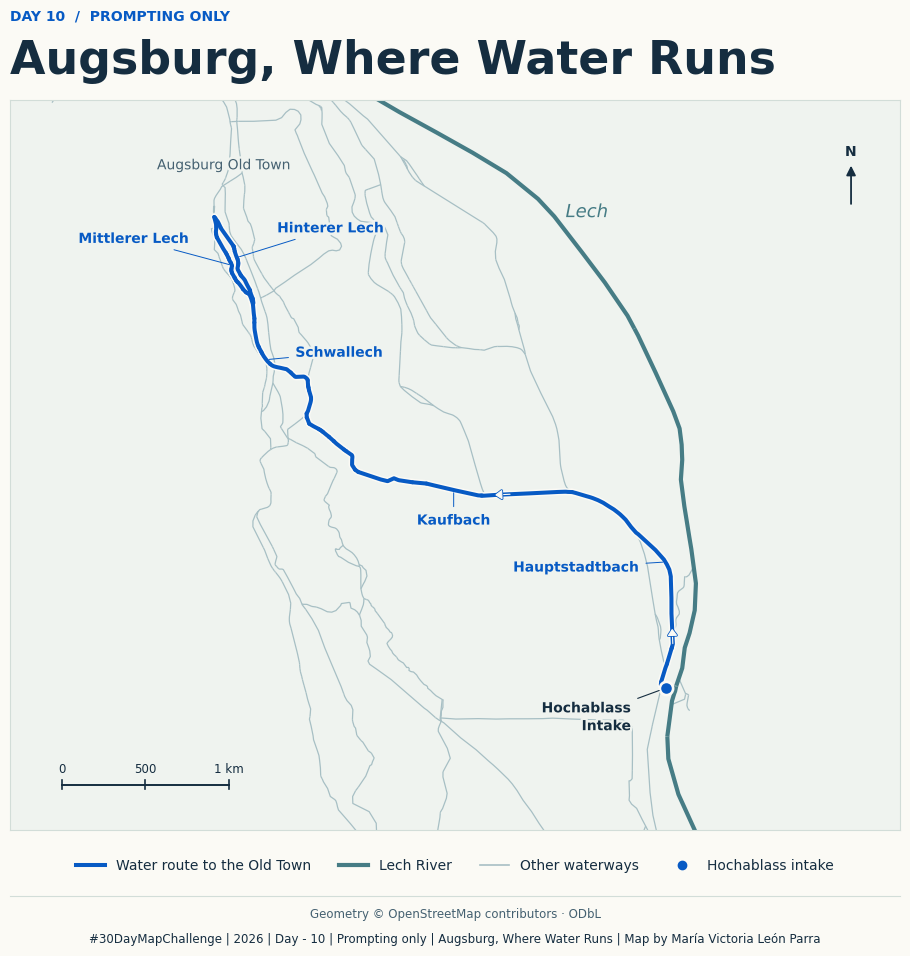

In [6]:
import matplotlib.pyplot as plt
from matplotlib import patheffects
from matplotlib.lines import Line2D
from shapely.ops import nearest_points

BASE_DIR = Path.cwd()
FIGURE_DIR = BASE_DIR / "output"
FIGURE_DIR.mkdir(exist_ok=True)

# Use a blue accent for the documented route and softer tones for other water.
paper = "#fbfaf5"
land = "#eff3ef"
ink = "#152d40"
muted = "#456171"
blue = "#075ac4"
river = "#467c85"
context = "#a7bfc4"

fig = plt.figure(figsize=(10, 10), facecolor=paper)
ax = fig.add_axes([0.055, 0.145, 0.89, 0.73], facecolor=land)
ax.set(xlim=(639480, 644810), ylim=(5355530, 5359900), aspect="equal")
ax.set_xticks([])
ax.set_yticks([])
for spine in ax.spines.values():
    spine.set(color="#d2ddd8", linewidth=0.8)

layers["context_waterways"].plot(ax=ax, color=context, linewidth=0.9, zorder=1)
layers["lech_river"].plot(ax=ax, color=river, linewidth=3.0, zorder=2)
layers["documented_route"].plot(
    ax=ax, color=paper, linewidth=5.1, capstyle="round", joinstyle="round", zorder=3
)
layers["documented_route"].plot(
    ax=ax, color=blue, linewidth=2.9, capstyle="round", joinstyle="round", zorder=4
)
layers["hochablass_intake"].plot(
    ax=ax, color=blue, edgecolor=paper, linewidth=1.9, markersize=91, zorder=5
)

fig.text(0.055, 0.965, "DAY 10  /  PROMPTING ONLY",
         color=blue, fontsize=10, fontweight="bold", va="top")
fig.text(0.055, 0.936, "Augsburg, Where Water Runs",
         color=ink, fontsize=33, fontweight="bold", va="top")

# Anchor each label to its own waterway, with offsets in typographic points.
route_layer = layers["documented_route"]
label_specs = [
    ("Hauptstadtbach", (643365, 5357110), (-19, -4), "right"),
    ("Kaufbach", (642144, 5357595), (0, -22), "center"),
    ("Schwallech", (641095, 5358410), (21, 5), "left"),
    ("Mittlerer Lech", (640804, 5358910), (-31, 19), "right"),
    ("Hinterer Lech", (640869, 5358970), (29, 21), "left"),
]
halo = [patheffects.withStroke(linewidth=3.5, foreground=land)]

# Show flow on two ways whose node order passed the directed route check.
flow_markers = [(161951712, (643445, 5356690)), (156428956, (642430, 5357530))]
route_by_id = route_layer.set_index("osm_id").geometry
for osm_id, target in flow_markers:
    way = route_by_id.loc[osm_id]
    distance = way.project(Point(target))
    upstream = way.interpolate(max(0, distance - 45))
    downstream = way.interpolate(min(way.length, distance + 45))
    marker = ax.annotate(
        "", xy=(downstream.x, downstream.y), xytext=(upstream.x, upstream.y),
        arrowprops={
            "arrowstyle": "-|>,head_length=0.42,head_width=0.29",
            "color": paper, "lw": 0.8, "mutation_scale": 10,
            "shrinkA": 0, "shrinkB": 0,
        },
        zorder=5,
    )
    marker.arrow_patch.set_path_effects([
        patheffects.withStroke(linewidth=2, foreground=blue)
    ])

ax.text(
    640760, 5359510, "Augsburg Old Town", ha="center", va="center",
    color=muted, fontsize=10, path_effects=halo, zorder=6,
)

for name, target, offset, alignment in label_specs:
    reach = route_layer.loc[route_layer["route_reach"].eq(name), "geometry"]
    anchor = nearest_points(Point(target), reach.union_all())[1]
    ax.annotate(
        name, (anchor.x, anchor.y), xytext=offset, textcoords="offset points",
        ha=alignment, va="center", color=blue, fontsize=10, fontweight="semibold",
        arrowprops={"arrowstyle": "-", "color": blue, "lw": 0.7, "shrinkA": 3, "shrinkB": 2},
        path_effects=halo, zorder=6,
    )

intake_point = layers["hochablass_intake"].geometry.iloc[0]
ax.annotate(
    "Hochablass\nIntake", (intake_point.x, intake_point.y), xytext=(-25, -21),
    textcoords="offset points", ha="right", va="center", color=ink,
    fontsize=10, fontweight="bold", linespacing=1.35,
    arrowprops={"arrowstyle": "-", "color": ink, "lw": 0.8, "shrinkA": 3, "shrinkB": 5},
    path_effects=halo, zorder=6,
)

river_anchor = nearest_points(
    Point(642630, 5359150), layers["lech_river"].geometry.union_all()
)[1]
ax.annotate(
    "Lech", (river_anchor.x, river_anchor.y), xytext=(11, 0),
    textcoords="offset points", ha="left", va="center",
    fontsize=13, fontstyle="italic", color=river, path_effects=halo, zorder=6,
)

# Indicate grid north in the projected coordinate system.
ax.annotate(
    "", xy=(0.945, 0.914), xytext=(0.945, 0.854), xycoords="axes fraction",
    arrowprops={"arrowstyle": "-|>", "color": ink, "lw": 1.3, "mutation_scale": 14},
    zorder=7,
)
ax.text(0.945, 0.923, "N", transform=ax.transAxes, ha="center",
        fontsize=10, color=ink, fontweight="bold")

# Draw a 1 km scale bar using projected metres.
scale_x, scale_y = 639790, 5355800
ax.plot([scale_x, scale_x + 1000], [scale_y, scale_y], color=ink, lw=1.4, zorder=7)
for metres, label in [(0, "0"), (500, "500"), (1000, "1 km")]:
    x = scale_x + metres
    ax.plot([x, x], [scale_y - 26, scale_y + 26], color=ink, lw=1.2, zorder=7)
    ax.text(x, scale_y + 53, label, color=ink, fontsize=8.5, ha="center", va="bottom")

# Keep the legend and attribution clear of the waterway labels.
legend_items = [
    Line2D([], [], color=blue, lw=2.9, label="Water route to the Old Town"),
    Line2D([], [], color=river, lw=3.0, label="Lech River"),
    Line2D([], [], color=context, lw=1.2, label="Other waterways"),
    Line2D([], [], color=blue, marker="o", markersize=6, linestyle="none",
           label="Hochablass intake"),
]
fig.legend(
    handles=legend_items, loc="center", bbox_to_anchor=(0.5, 0.109), ncol=4,
    frameon=False, fontsize=10, labelcolor=ink, handlelength=2.1, columnspacing=2.0,
)

fig.add_artist(Line2D([0.055, 0.945], [0.079, 0.079],
                      transform=fig.transFigure, color="#d2ddd8", lw=0.8))
fig.text(0.5, 0.057, "Geometry © OpenStreetMap contributors · ODbL",
         ha="center", color=muted, fontsize=8.5)
fig.text(
    0.5, 0.032,
    "#30DayMapChallenge | 2026 | Day - 10 | Prompting only | "
    "Augsburg, Where Water Runs | Map by María Victoria León Parra",
    ha="center", color=ink, fontsize=8.5,
)

plt.show()

In [7]:
# Export at 300 dpi with the full square canvas and its background.
map_path = FIGURE_DIR / "day10_prompting_only_augsburg_refined.png"
fig.savefig(map_path, dpi=300, facecolor=fig.get_facecolor())
print(f"Refined map saved to {map_path.relative_to(BASE_DIR)}.")

Refined map saved to output\day10_prompting_only_augsburg_refined.png.


## Sources and limitations

- Geometry © [OpenStreetMap contributors](https://www.openstreetmap.org/copyright), ODbL.
- The city’s [Hochablass](https://wassersystem-augsburg.de/de/objekte/hochablass-lechwehr) and [Lechkanäle](https://wassersystem-augsburg.de/de/objekte/lechkanaele) profiles identify the intake and the separate Lochbach supply to Vorderer Lech. The [nomination dossier](https://wassersystem-augsburg.de/sites/default/files/2022-11/1_stadt_augsburg_nomination_dossier_0.pdf#page=139) traces the selected branches.
- Prompting workflow inspired by Tyson Swetnam’s [Vibe coding a Public Health Map](https://tyson-swetnam.github.io/intro-gpt/tutorials/publichealth/gis/). The original instructions are in [prompt.md](prompt.md).

The intake point is the mapped start node of Hauptstadtbach. The route follows mapped channel centrelines and covers the selected connection to the old town. The context layer includes other waterways in the study area, some of which also receive water from Hochablass.